In [10]:
# import pandas as pd

# a = pd.read_parquet("data/raw/train-00000-of-00002.parquet")
# b = pd.read_parquet("data/raw/train-00001-of-00002.parquet")
# print(list(a.columns) == list(b.columns))

# df = pd.concat([a, b], ignore_index=True).drop_duplicates()
# df.to_parquet("data/raw/combined.parquet", index=False)
# print(df.shape)

True
(357734, 12)


In [22]:
import pandas as pd

df = pd.read_parquet("data/raw/combined.parquet")
df["dt"] = pd.to_datetime(df["Date"], utc=True, errors="coerce")
print(df["dt"].min(), df["dt"].max())
print(df.groupby(df["dt"].dt.year).size())

top = df["Stock_symbol"].value_counts().head(30).index
print(list(top))
df[df["Stock_symbol"].isin(top)].to_parquet("data/raw/top30.parquet", index=False)

2009-07-07 00:00:00+00:00 2024-01-09 00:00:00+00:00
dt
2009      324
2010     3522
2011     6384
2012     9879
2013    10877
2014    15213
2015    21712
2016    23306
2017    30301
2018    38885
2019    41206
2020    32954
2021    19795
2022    39404
2023    63902
2024       70
dtype: int64
['GILD', 'NVDA', 'INTC', 'TSLA', 'GOOG', 'MU', 'AAPL', 'AMD', 'QCOM', 'CMCSA', 'MSFT', 'SBUX', 'EBAY', 'PEP', 'EA', 'WBA', 'TXN', 'COST', 'ADBE', 'BIIB', 'PANW', 'PYPL', 'CSX', 'VRTX', 'AMGN', 'AMZN', 'SIRI', 'DLTR', 'TMUS', 'AMAT']


In [1]:
import hashlib, pandas as pd
d = pd.read_parquet("data/raw/top30.parquet")
print(d.shape, d['Article'].isna().mean())

(226532, 13) 0.0


In [2]:
d.head(3)

,Unnamed: 0,Date,Article_title,Stock_symbol,Url,Publisher,Author,Article,Lsa_summary,Luhn_summary,Textrank_summary,Lexrank_summary,dt
0,12025.0,2023-12-16 22:00:00 UTC,My 6 Largest Portfolio Holdings Heading Into 2...,AAPL,https://www.nasdaq.com/articles/my-6-largest-p...,,,"After an absolute disaster of a year in 2022, ...",3: Apple There's little question that Apple (N...,3: Apple There's little question that Apple (N...,3: Apple There's little question that Apple (N...,3: Apple There's little question that Apple (N...,2023-12-16 22:00:00+00:00
1,12026.0,2023-12-16 22:00:00 UTC,Brokers Suggest Investing in Apple (AAPL): Rea...,AAPL,https://www.nasdaq.com/articles/brokers-sugges...,,,"When deciding whether to buy, sell, or hold a ...",Let's take a look at what these Wall Street he...,Click to get this free report Apple Inc. (AAPL...,Let's take a look at what these Wall Street he...,Brokerage Recommendation Trends for AAPL Let's...,2023-12-16 22:00:00+00:00
2,12027.0,2023-12-16 21:00:00 UTC,"Company News for Dec 19, 2023",AAPL,https://www.nasdaq.com/articles/company-news-f...,,,Shares of Apple Inc. AAPL lost 0.9% on China’s...,Shares of Apple Inc. AAPL lost 0.9% on China’s...,Click to get this free report Apple Inc. (AAPL...,Click to get this free report Apple Inc. (AAPL...,Click to get this free report Apple Inc. (AAPL...,2023-12-16 21:00:00+00:00


In [3]:
print(d.isna().sum())

Unnamed: 0          0
Date                0
Article_title       0
Stock_symbol        0
Url                 0
Publisher           0
Author              0
Article             0
Lsa_summary         0
Luhn_summary        0
Textrank_summary    0
Lexrank_summary     0
dt                  0
dtype: int64


In [4]:
full = pd.read_parquet("data/raw/combined.parquet")          # dropping ea and wba, as they were delisted
ranked = [t for t in full["Stock_symbol"].value_counts().index if t not in ("EA", "WBA")]
keep = ranked[:30]
d = full[full["Stock_symbol"].isin(keep)].copy()
d = d.drop(columns=["Unnamed: 0", "dt", "Author", "Publisher",
                    "Lsa_summary", "Luhn_summary"], errors="ignore")
print(d.columns.tolist())
print(keep)

['Date', 'Article_title', 'Stock_symbol', 'Url', 'Article', 'Textrank_summary', 'Lexrank_summary']
['GILD', 'NVDA', 'INTC', 'TSLA', 'GOOG', 'MU', 'AAPL', 'AMD', 'QCOM', 'CMCSA', 'MSFT', 'SBUX', 'EBAY', 'PEP', 'TXN', 'COST', 'ADBE', 'BIIB', 'PANW', 'PYPL', 'CSX', 'VRTX', 'AMGN', 'AMZN', 'SIRI', 'DLTR', 'TMUS', 'AMAT', 'ADI', 'AVGO']


In [ ]:
import yfinance as yf
px = yf.download(keep + ["^GSPC"], start="2008-06-01", end="2025-01-15",
                 auto_adjust=True, progress=False, threads=False)["Close"]
px.to_parquet("data/prices.parquet")
print(px.shape)
print(px.isna().sum().sort_values().tail(5))

(4183, 31)
Ticker
TXN        0
AVGO     298
TSLA     523
PANW    1043
PYPL    1785
dtype: int64


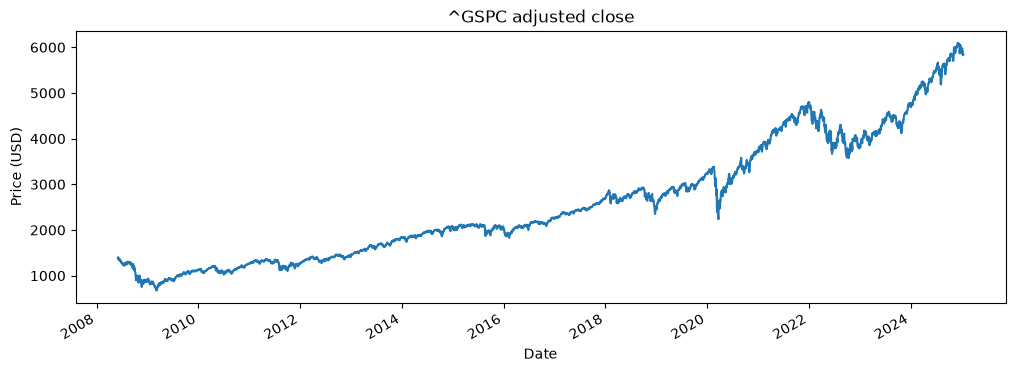

In [7]:
import matplotlib.pyplot as plt
symbol = "^GSPC"
px[symbol].dropna().plot(figsize=(12, 4), title=f"{symbol} adjusted close")
plt.ylabel("Price (USD)")
plt.show()

In [8]:
d.columns

Index(['Date', 'Article_title', 'Stock_symbol', 'Url', 'Article',
       'Textrank_summary', 'Lexrank_summary'],
      dtype='str')

In [10]:
import hashlib, numpy as np, pandas as pd

ts = pd.to_datetime(d["Date"], utc=True, errors="coerce")
x, t = d[ts.notna()], ts[ts.notna()]

title = x["Article_title"].fillna("").str.strip()
art = x["Article"].fillna("")
lex = x["Lexrank_summary"].fillna("").str.strip()
pt = ((t - pd.Timestamp("1970-01-01", tz="UTC")).dt.total_seconds()).astype("int64")

is_long = (title + ". " + art).str.len() > 5000
use_sum = is_long & (lex.str.len() > 0)

docs = pd.DataFrame({
    "ticker": x["Stock_symbol"],
    "title": title,
    "text": (title + ". " + art).str.slice(0, 3000),
    "embed_text": (title + ". " + lex).where(use_sum, title + ". " + art),
    "embed_source": np.where(use_sum, "summary", "article"),
    "publish_time": pt,
    "date_only": t.dt.strftime("%H:%M:%S") == "00:00:00",
    "source_type": "news",
    "source_name": "nasdaq",
    "url": x["Url"],
    "textrank_summary": x["Textrank_summary"],
    "lexrank_summary": x["Lexrank_summary"],
})
docs = docs[docs["text"].str.len() > 40]
docs = docs.drop_duplicates(subset=["ticker", "title", "publish_time"]).reset_index(drop=True)
docs["doc_id"] = [hashlib.sha1(f"{a}|{b}|{c}".encode()).hexdigest()[:16]
                  for a, b, c in zip(docs.ticker, docs.publish_time, docs.title)]

print(docs.shape)
print(docs.embed_source.value_counts())
docs.to_parquet("data/processed_docs.parquet", index=False)

(209262, 13)
embed_source
article    148279
summary     60983
Name: count, dtype: int64


In [ ]:
from sentence_transformers import SentenceTransformer
import chromadb

sample = docs.sample(1000, random_state=42).reset_index(drop=True)
model = SentenceTransformer("BAAI/bge-small-en-v1.5")
model.max_seq_length = 512
emb = model.encode(sample.embed_text.tolist(), batch_size=32,
                   normalize_embeddings=True, show_progress_bar=True)

col = chromadb.PersistentClient(path="data/chroma_test2").get_or_create_collection(
    "news_test2", metadata={"hnsw:space": "cosine"})
col.upsert( 
    ids=sample.doc_id.tolist(),
    embeddings=emb.tolist(),
    documents=sample.text.tolist(),
    metadatas=[{"ticker": r.ticker, "publish_timea": int(r.publish_time),
                "title": r.title, "url": r.url or "",
                "embed_source": r.embed_source,
                "lexrank_summary": r.lexrank_summary or ""}
               for r in sample.itertuples()],
)
print(col.count())

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

c:\Users\Krishna\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Krishna\.cache\huggingface\hub\models--BAAI--bge-small-en-v1.5. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

... (7 outputs left out)

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/32 [00:00<?, ?it/s]

1000


In [28]:
# def search(q, as_of, ticker=None, k=5):
#     lim = int(pd.Timestamp(as_of, tz="UTC").timestamp())
#     cond = [{"publish_time": {"$lte": lim}}]
#     if ticker:
#         cond.append({"ticker": ticker})
#     where = cond[0] if len(cond) == 1 else {"$and": cond}
#     qe = model.encode([q], normalize_embeddings=True).tolist()
#     return col.query(query_embeddings=qe, n_results=k, where=where), lim

# # 1) as-of test: nothing after the cutoff may come back
# for as_of in ["2012-01-01", "2016-06-30", "2020-03-01", "2023-01-01"]:
#     r, lim = search("earnings and guidance", as_of, k=20)
#     times = [m["publish_time"] for m in r["metadatas"][0]]
#     assert all(t <= lim for t in times), f"LEAK at {as_of}"
#     print(as_of, "OK,", len(times), "results")



# r, _ = search("NVIDIA earnings and AI demand", "2023-06-30", "NVDA")

# for doc_id, doc, m, dist in zip(r["ids"][0], r["documents"][0], r["metadatas"][0], r["distances"][0]):
#     print({
#         "id": doc_id,
#         "distance": dist,
#         "date": str(pd.to_datetime(m["publish_time"], unit="s").date()),
#         **m,
#         "document": doc,
#     })

In [27]:
rets = px.pct_change()

def show(q, as_of, ticker=None, k=5):
    r, lim = search(q, as_of, ticker, k)
    metas, dists = r["metadatas"][0], r["distances"][0]
    print(f"Query: {q} | as_of={as_of} | ticker={ticker}")
    for m, dist in zip(metas, dists):
        day0 = pd.to_datetime(m["publish_time"], unit="s").normalize()
        i = rets.index.searchsorted(day0)          # first trading day on/after the article date
        if i >= len(rets):
            continue
        tk = m["ticker"]
        s, mk = rets[tk].iloc[i], rets["^GSPC"].iloc[i]
        print(f"{day0.date()} {tk:5} sim={1-dist:.3f} {m['embed_source']:7} "
              f"stock={s:+.2%} index={mk:+.2%} abn={s-mk:+.2%} | {m['title'][:55]}")
    last = max(m["publish_time"] for m in metas)
    print(f"results={len(metas)} | mean sim={1-sum(dists)/len(dists):.3f} | "
          f"latest article <= as_of: {last <= lim}\n")

show("NVIDIA earnings and AI demand", "2023-06-30", "NVDA")
show("quarterly earnings and guidance", "2016-06-30")

Query: NVIDIA earnings and AI demand | as_of=2023-06-30 | ticker=NVDA
2023-06-27 NVDA  sim=0.798 summary stock=+3.06% index=+1.15% abn=+1.92% | This Nvidia Rival Could Become the Next Hot AI Play, an
2019-11-15 NVDA  sim=0.785 article stock=-2.67% index=+0.77% abn=-3.44% | UPDATE: Raymond James Reiterates Outperform On NVIDIA, 
2023-06-22 NVDA  sim=0.775 summary stock=-0.05% index=+0.37% abn=-0.42% | Nvidia DGX: Workhorse of AI Will Drive NVDA to $2 Trill
2023-05-23 NVDA  sim=0.773 summary stock=-1.57% index=-1.12% abn=-0.44% | Bulls vs. Bears - Who Will Emerge Victorious?
2023-04-25 NVDA  sim=0.761 article stock=-2.96% index=-1.58% abn=-1.38% | 2 No-Brainer Tech Stocks to Buy With $1,000
results=5 | mean sim=0.779 | latest article <= as_of: True

Query: quarterly earnings and guidance | as_of=2016-06-30 | ticker=None
2010-11-19 ADI   sim=0.743 article stock=+1.82% index=+0.25% abn=+1.57% | Stuffing the Turkey with Data - Earnings Preview
2012-07-19 ADI   sim=0.701 article stock=+1.06%

In [29]:
import math, random
import pandas as pd

DAY = 86400
ts = lambda d: int(pd.Timestamp(d, tz="UTC").timestamp())

def month_edges(s_ts, e_ts):
    s = pd.Timestamp(s_ts, unit="s", tz="UTC")
    e = pd.Timestamp(e_ts, unit="s", tz="UTC")
    edges, cur = [s], s.normalize().replace(day=1) + pd.offsets.MonthBegin(1)
    while cur <= e:
        edges.append(cur)
        cur += pd.offsets.MonthBegin(1)
    edges.append(e + pd.Timedelta(seconds=1))
    return [int(x.timestamp()) for x in edges]

def run_query(qe, ticker, lo, hi, n):
    conds = []
    if lo is not None: conds.append({"publish_time": {"$gte": lo}})
    if hi is not None: conds.append({"publish_time": {"$lte": hi}})
    if ticker: conds.append({"ticker": ticker})
    where = None if not conds else conds[0] if len(conds) == 1 else {"$and": conds}
    r = col.query(query_embeddings=qe, n_results=n, where=where,
                  include=["metadatas", "documents", "distances"])
    return [{"doc_id": i, **m, "text": t, "sim": 1 - d}
            for i, m, t, d in zip(r["ids"][0], r["metadatas"][0],
                                  r["documents"][0], r["distances"][0])]

def retrieve(query, ticker, start, end, as_of,
             k_per_bucket=3, n_candidates=10, k_total=15,
             use_asof=True, use_window=True, use_decay=True, use_buckets=True,
             alpha=0.7, half_life=30):
    # Plain-RAG baseline: use_window=False, use_asof=False, use_decay=False, use_buckets=False
    qe = model.encode([query], normalize_embeddings=True).tolist()
    as_of_ts = ts(as_of) + DAY - 1              # as_of = end of that UTC day, inclusive
    lo, hi = ts(start), ts(end) + DAY - 1
    if use_asof:
        hi = min(hi, as_of_ts)                  # window can never pass the cutoff
    if not use_window:
        lo = hi = None                          # no date logic at all
        use_buckets = False

    if use_buckets:
        edges = month_edges(lo, hi)
        rows = []
        for i in range(len(edges) - 1):
            rows += [dict(r, bucket=i)
                     for r in run_query(qe, ticker, edges[i], edges[i + 1] - 1, n_candidates)]
    else:
        rows = [dict(r, bucket=0) for r in run_query(qe, ticker, lo, hi, 50)]

    df = pd.DataFrame(rows)
    if df.empty:
        return df
    age = ((as_of_ts - df.publish_time) / DAY).clip(lower=0)
    df["decay"] = (-math.log(2) * age / half_life).map(math.exp)
    df["score"] = alpha * df.sim + (1 - alpha) * df.decay if use_decay else df.sim
    df = df.sort_values("score", ascending=False)
    df = df.groupby("bucket").head(k_per_bucket) if use_buckets else df.head(k_total)
    df["date"] = pd.to_datetime(df.publish_time, unit="s").dt.date
    df = df.sort_values("publish_time").reset_index(drop=True)

    if use_asof:                                 # belt and braces
        assert (df.publish_time <= as_of_ts).all(), "LEAK: article after as_of"
    return df

In [15]:
import os
from typing import Literal
import pandas as pd
from openai import OpenAI
from pydantic import BaseModel, Field
from dotenv import load_dotenv
load_dotenv()  

client = OpenAI(base_url="https://openrouter.ai/api/v1",
                api_key=os.environ["OPENROUTER_API_KEY"])      # no key in the code

class RetrievalInput(BaseModel):
    ticker: str = Field(description="Uppercase stock ticker, e.g. NVDA")
    search_query: str = Field(description="Short semantic search phrase, no dates or instructions")
    start: str = Field(description="Start date, YYYY-MM-DD")
    end: str = Field(description="End date, YYYY-MM-DD")
    as_of: str = Field(description="Knowledge cutoff date, YYYY-MM-DD")
    tasks: list[Literal["trend", "event_impact", "point_lookup"]] = Field(
        description="Every task the question asks for. A question can need more than one.")
    event_hint: str = Field(description="Event phrase such as 'May earnings', or empty string if none")

SYSTEM_PROMPT = f"""Extract structured arguments from the user's financial question.
Rules:
- ticker: map company names to tickers. Valid tickers: {', '.join(keep)}.
- Convert month or quarter ranges to exact dates ('Jan to Jun 2023' -> start 2023-01-01, end 2023-06-30).
- If the user says 'as of <date>', set as_of to that date. Otherwise set as_of equal to end.
- tasks: 'trend' for how sentiment or coverage changed over time, 'event_impact' for how the market
  reacted to an event, 'point_lookup' for what was the latest news at a date. Include all that apply.
- event_hint: the event phrase only (for example 'May earnings'); empty string if none.
- search_query: the financial topic only."""

def extract_params(user_text, model="openrouter/free"):
    schema = RetrievalInput.model_json_schema()
    schema["additionalProperties"] = False
    resp = client.chat.completions.create(
        model=model, temperature=0,
        messages=[{"role": "system", "content": SYSTEM_PROMPT},
                  {"role": "user", "content": user_text}],
        response_format={"type": "json_schema",
                         "json_schema": {"name": "retrieval_input", "strict": True, "schema": schema}},
        extra_body={"provider": {"require_parameters": True},
                    "plugins": [{"id": "response-healing"}]},
    )
    return RetrievalInput.model_validate_json(resp.choices[0].message.content)

NameError: name 'keep' is not defined

In [12]:
ticker = "NVDA"
user_msg = (
    "How did sentiment around NVDA change from Jan to Jun 2024, "
    "and how did the market react to its May earnings? Answer as of 31 May 2024."
)

params = extract_params(user_msg)
print("Extracted:", params.model_dump())

Extracted: {'query': 'NVDA sentiment shift and market reaction to May 2024 earnings', 'start': '2024-01-01', 'end': '2024-06-30', 'as_of': '2024-05-31', 'intent': 'trend'}


In [ ]:
res = retrieve(
    query=params.query,
    ticker=ticker,
    start=params.start,
    end=params.end,
    as_of=params.as_of,
)
print(res[["date", "bucket", "sim", "decay", "score", "embed_source", "title"]].to_string())